# 01 · Preprocessing — Zhou 2020 Osteosarcoma (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven multiplicative
gap**, integrate patients (Harmony), embed, remove detached islands, and split the
manifold into its transcriptional compartments. Osteosarcoma is a mesenchymal
malignancy whose malignant cells span an osteoblastic body, a chondroblastic tip and
a proliferating compartment; as in the reference runs the manifold resolves into a
**cycling** lobe and a **low-cycling** lobe. Whether the gastrulation / somitogenesis
/ neural-crest developmental axis is confined to one lobe (Kürten 2021) or spans both
(Bischoff / Sun 2021) is **derived in 02 from the signature geography**, not assumed
here, so both compartments are carried forward. Every tunable choice is *derived from
this dataset*, not inherited. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Zhou2020_Sarcoma | category: Sarcoma


### Load malignant compartment
Zhou et al. annotate `cell_type` as **lineage** (Osteoblast / Chondrocyte /
Osteoblast_proli / stromal / immune), so the loader's `celltype` alias is the lineage
label, **not** a malignancy call. Malignancy is a separate inferCNV call in
`obs['malignant']`; we take their `malignant == 'yes'` cells (the publication's
Malignant calls, per protocol).

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['malignant'] == 'yes'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('malignant lineages (cell_type):', adata.obs['cell_type'].value_counts().to_dict())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Zhou2020_Sarcoma
/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
Done.
full atlas: (64557, 32864)
malignant: (33459, 32864) | samples: 11
malignant lineages (cell_type): {'Osteoblast': 20180, 'Chondrocyte': 7098, 'Osteoblast_proli': 6181}
expression: X max 8.34 (log1p of normalize_total counts)


### Sample thresholding — derived by multiplicative gap-finding
Per-sample malignant counts span an order of magnitude. Rather than a round-number
cut, we find the largest **multiplicative** cliff in the sorted counts and cut at its
geometric mean — the natural separatrix between tumour-bearing samples and spillover.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [6265 5119 5100 5053 3393 3032 2665 1172 1007  357  296]
largest gap: 1007 -> 357 (ratio 2.82)
derived threshold (geometric mean across the gap) = 599
kept 9/11 samples -> 32806 cells


### Overdispersion, PCA, Harmony integration, embedding
`theta` is selected by a same-sample-neighbour-fraction sweep (lower = better mixing):
we take the theta past which mixing plateaus. Osteosarcoma malignant cells are strongly
patient-specific (distinct CNVs), so the strongest theta is chosen. PC count (20) and
UMAP spread (1.3) follow the 10x precedents (Kürten / Sun / Lee, comparable cell counts).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

# theta sweep: same-sample neighbour fraction (lower = better batch mixing)
from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing plateaus; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2315 over-dispersed features (0:00:08) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2315
2026-07-31 18:00:44,919 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-07-31 18:00:54,659 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-07-31 18:00:54,990 - harmonypy - INFO - Iteration 1 of 30
2026-07-31 18:01:08,936 - harmonypy - INFO - Iteration 2 of 30
2026-07-31 18:01:22,392 - harmonypy - INFO - Converged after 2 iterations
2026-07-31 18:01:24,980 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-07-31 18:01:33,813 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-07-31 18:01:34,173 - harmonypy - INFO - Iteration 1 

### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop
any cell outside the main connected component — stripping physically detached specks
while keeping the continuous arm termini.

In [6]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()

removed 0 cells in 0 detached islands


### Compartment split + labelling (data-driven)
Low-resolution Leiden (res=0.15) recovers the manifold's lobes. We label them *by
biology*: the compartment with the **lower cycling fraction** is the **Embryonic**
candidate; the rest are **Cycling/Metabolic**. `cell_cycle_phase` comes from the
publication's phase calls. Whether the trajectory is scoped to one lobe or spans all
is decided in 02 from the signature geography, not assumed here.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
emb_lobe = cyc.idxmin()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(2).to_dict())
lab_map = {l: ('Embryonic' if l==emb_lobe else 'Cycling/Metabolic')
           for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'1': 22156, '0': 10650}
cycling fraction per lobe: {'0': 0.53, '1': 0.05}
compartments: {'Embryonic': 22156, 'Cycling/Metabolic': 10650}


### House orientation — one consistent layout for every UMAP
The developmental axis is **diagonal** in the raw joint embedding, so all trajectory
panels are shown after a single **rigid rotation** to the house horizontal layout
(distance-preserving — *not* a re-embedding). The orientation is derived **once here**,
stored as `X_umap_lin`, and re-used unchanged by 02/03/04 so every deliverable UMAP
shares one orientation (binding). Two ingredients, both available pre-trajectory:
(i) the rotation angle = the manifold's **axis of maximal variance** (the elongated
strip's major axis; aspect ratio well above 1 confirms a dominant axis exists), and
(ii) the sign = put the **proliferating-progenitor pole on the left** (the developmental
origin: the compartment with the higher cycling fraction), so pseudotime will run
left→right once fit in 02. This reproduces the pseudotime-based orientation to within a
few degrees (the strip's major axis ≈ the developmental axis) without depending on the
trajectory, keeping 01 self-contained.

In [8]:
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)          # vt[0] = axis of maximal variance
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[ np.cos(-theta_rot), -np.sin(-theta_rot)],
               [ np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
cyc = adata.obs['cycling'].values.astype(float)           # progenitor/high-cycling pole -> left
if np.average(xyr[:,0], weights=cyc) > 0:
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), '
      f'progenitor pole on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.50
house orientation: rigid rotation -165.9deg (distances preserved), progenitor pole on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. The read is
made on the regenerated embedding itself plus a per-neighbourhood metric (iLISI across
the theta sweep), not a scalar alone; the deliverable `samples.pdf` follows.

In [9]:
n_samp = adata.obs['sample'].nunique()
# per-neighbourhood mixing: iLISI (effective #samples in each cell's 90-NN neighbourhood)
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold (one connected component after island removal);')
print('both compartments contain multiple samples.')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 4.51 of 9 samples
9 samples share one continuous manifold (one connected component after island removal);
both compartments contain multiple samples.
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS


### Save processed data
Zhou's `Cells.csv` carries mixed-type metadata columns (per-cell meta-program scores
with blanks); coerce object columns to numeric where possible, else string, so the
manifold is h5ad-serializable. Analysis-relevant columns (`sample`, `cell_type`,
`cell_cycle_phase`, `malignant`, scores, compartment) are preserved.

In [10]:
for c in adata.obs.columns:
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (32806, 24692)


### Sample-integration figure (deliverable)

saved samples.pdf | cells: 32806


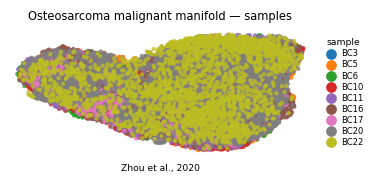

In [11]:
# Deliverable in house style (figsize=(3.5,1.5) horizontal strip, size=30) to match every
# other trajectory panel. The full malignant manifold is shown (the trajectory is scoped in
# 02; here we show all cells that enter it). Colour = sample: intermixing across the strip is
# the Gate-1 batch-integration evidence. Shown on the house orientation (X_umap_lin) derived
# above, so this panel shares one consistent orientation with the 02/03/04 UMAPs (binding).
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Osteosarcoma malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Zhou et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])